In [56]:
# dependencies

import numpy as np
import pandas as pd

import seaborn as sns
import matplotlib.pyplot as plt
import scipy.stats as stats

from sklearn.preprocessing import PowerTransformer
from sklearn.model_selection import train_test_split,cross_val_score
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score

In [57]:
# data

data= pd.read_csv('concrete_data.csv')

In [58]:
data.head()

,Cement,Blast Furnace Slag,Fly Ash,Water,Superplasticizer,Coarse Aggregate,Fine Aggregate,Age,Strength
0,540.0,0.0,0.0,162.0,2.5,1040.0,676.0,28,79.99
1,540.0,0.0,0.0,162.0,2.5,1055.0,676.0,28,61.89
2,332.5,142.5,0.0,228.0,0.0,932.0,594.0,270,40.27
3,332.5,142.5,0.0,228.0,0.0,932.0,594.0,365,41.05
4,198.6,132.4,0.0,192.0,0.0,978.4,825.5,360,44.30


In [59]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1030 entries, 0 to 1029
Data columns (total 9 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   Cement              1030 non-null   float64
 1   Blast Furnace Slag  1030 non-null   float64
 2   Fly Ash             1030 non-null   float64
 3   Water               1030 non-null   float64
 4   Superplasticizer    1030 non-null   float64
 5   Coarse Aggregate    1030 non-null   float64
 6   Fine Aggregate      1030 non-null   float64
 7   Age                 1030 non-null   int64  
 8   Strength            1030 non-null   float64
dtypes: float64(8), int64(1)
memory usage: 72.6 KB


In [60]:
data.shape

(1030, 9)

 this is dataset which shows the various factors of a cement like chemical composition and based on that the strength of the cement ,
 
 so its a regression problem -- we need to predict the strength of cement

In [61]:
data.describe()

,Cement,Blast Furnace Slag,Fly Ash,Water,Superplasticizer,Coarse Aggregate,Fine Aggregate,Age,Strength
count,1030.000000,1030.000000,1030.000000,1030.000000,1030.000000,1030.000000,1030.000000,1030.000000,1030.000000
mean,281.167864,73.895825,54.188350,181.567282,6.204660,972.918932,773.580485,45.662136,35.817961
std,104.506364,86.279342,63.997004,21.354219,5.973841,77.753954,80.175980,63.169912,16.705742
min,102.000000,0.000000,0.000000,121.800000,0.000000,801.000000,594.000000,1.000000,2.330000
25%,192.375000,0.000000,0.000000,164.900000,0.000000,932.000000,730.950000,7.000000,23.710000
50%,272.900000,22.000000,0.000000,185.000000,6.400000,968.000000,779.500000,28.000000,34.445000
75%,350.000000,142.950000,118.300000,192.000000,10.200000,1029.400000,824.000000,56.000000,46.135000
max,540.000000,359.400000,200.100000,247.000000,32.200000,1145.000000,992.600000,365.000000,82.600000


here we can see that some col have 0 as min values and no negative values ,
but since there is 0 as value we cant use box-cox in those col

In [62]:
x = data.drop(columns=['Strength'])

In [63]:
y= data['Strength']

In [64]:
x.head()

,Cement,Blast Furnace Slag,Fly Ash,Water,Superplasticizer,Coarse Aggregate,Fine Aggregate,Age
0,540.0,0.0,0.0,162.0,2.5,1040.0,676.0,28
1,540.0,0.0,0.0,162.0,2.5,1055.0,676.0,28
2,332.5,142.5,0.0,228.0,0.0,932.0,594.0,270
3,332.5,142.5,0.0,228.0,0.0,932.0,594.0,365
4,198.6,132.4,0.0,192.0,0.0,978.4,825.5,360


In [65]:
y.head()

0    79.99
1    61.89
2    40.27
3    41.05
4    44.30
Name: Strength, dtype: float64

In [66]:
x_train,x_test,y_train,y_test = train_test_split(x,y,
                                                test_size=0.2,
                                                random_state=42)

In [67]:
x_train.head()

,Cement,Blast Furnace Slag,Fly Ash,Water,Superplasticizer,Coarse Aggregate,Fine Aggregate,Age
995,158.6,148.9,116.0,175.1,15.0,953.3,719.7,28
507,424.0,22.0,132.0,178.0,8.5,822.0,750.0,28
334,275.1,0.0,121.4,159.5,9.9,1053.6,777.5,3
848,252.0,97.0,76.0,194.0,8.0,835.0,821.0,28
294,168.9,42.2,124.3,158.3,10.8,1080.8,796.2,3


In [68]:
# applying linear regression without transformation

lr = LinearRegression()

lr.fit(x_train,y_train)

y_pred = lr.predict(x_test)

r2_score(y_test,y_pred)

0.6275531792314851

In [69]:
# cross check
lr = LinearRegression()

np.mean(cross_val_score(lr,x,y,scoring='r2', cv=10))

0.27820729160873764

In [70]:
#  as we can see the condition of model is even worst

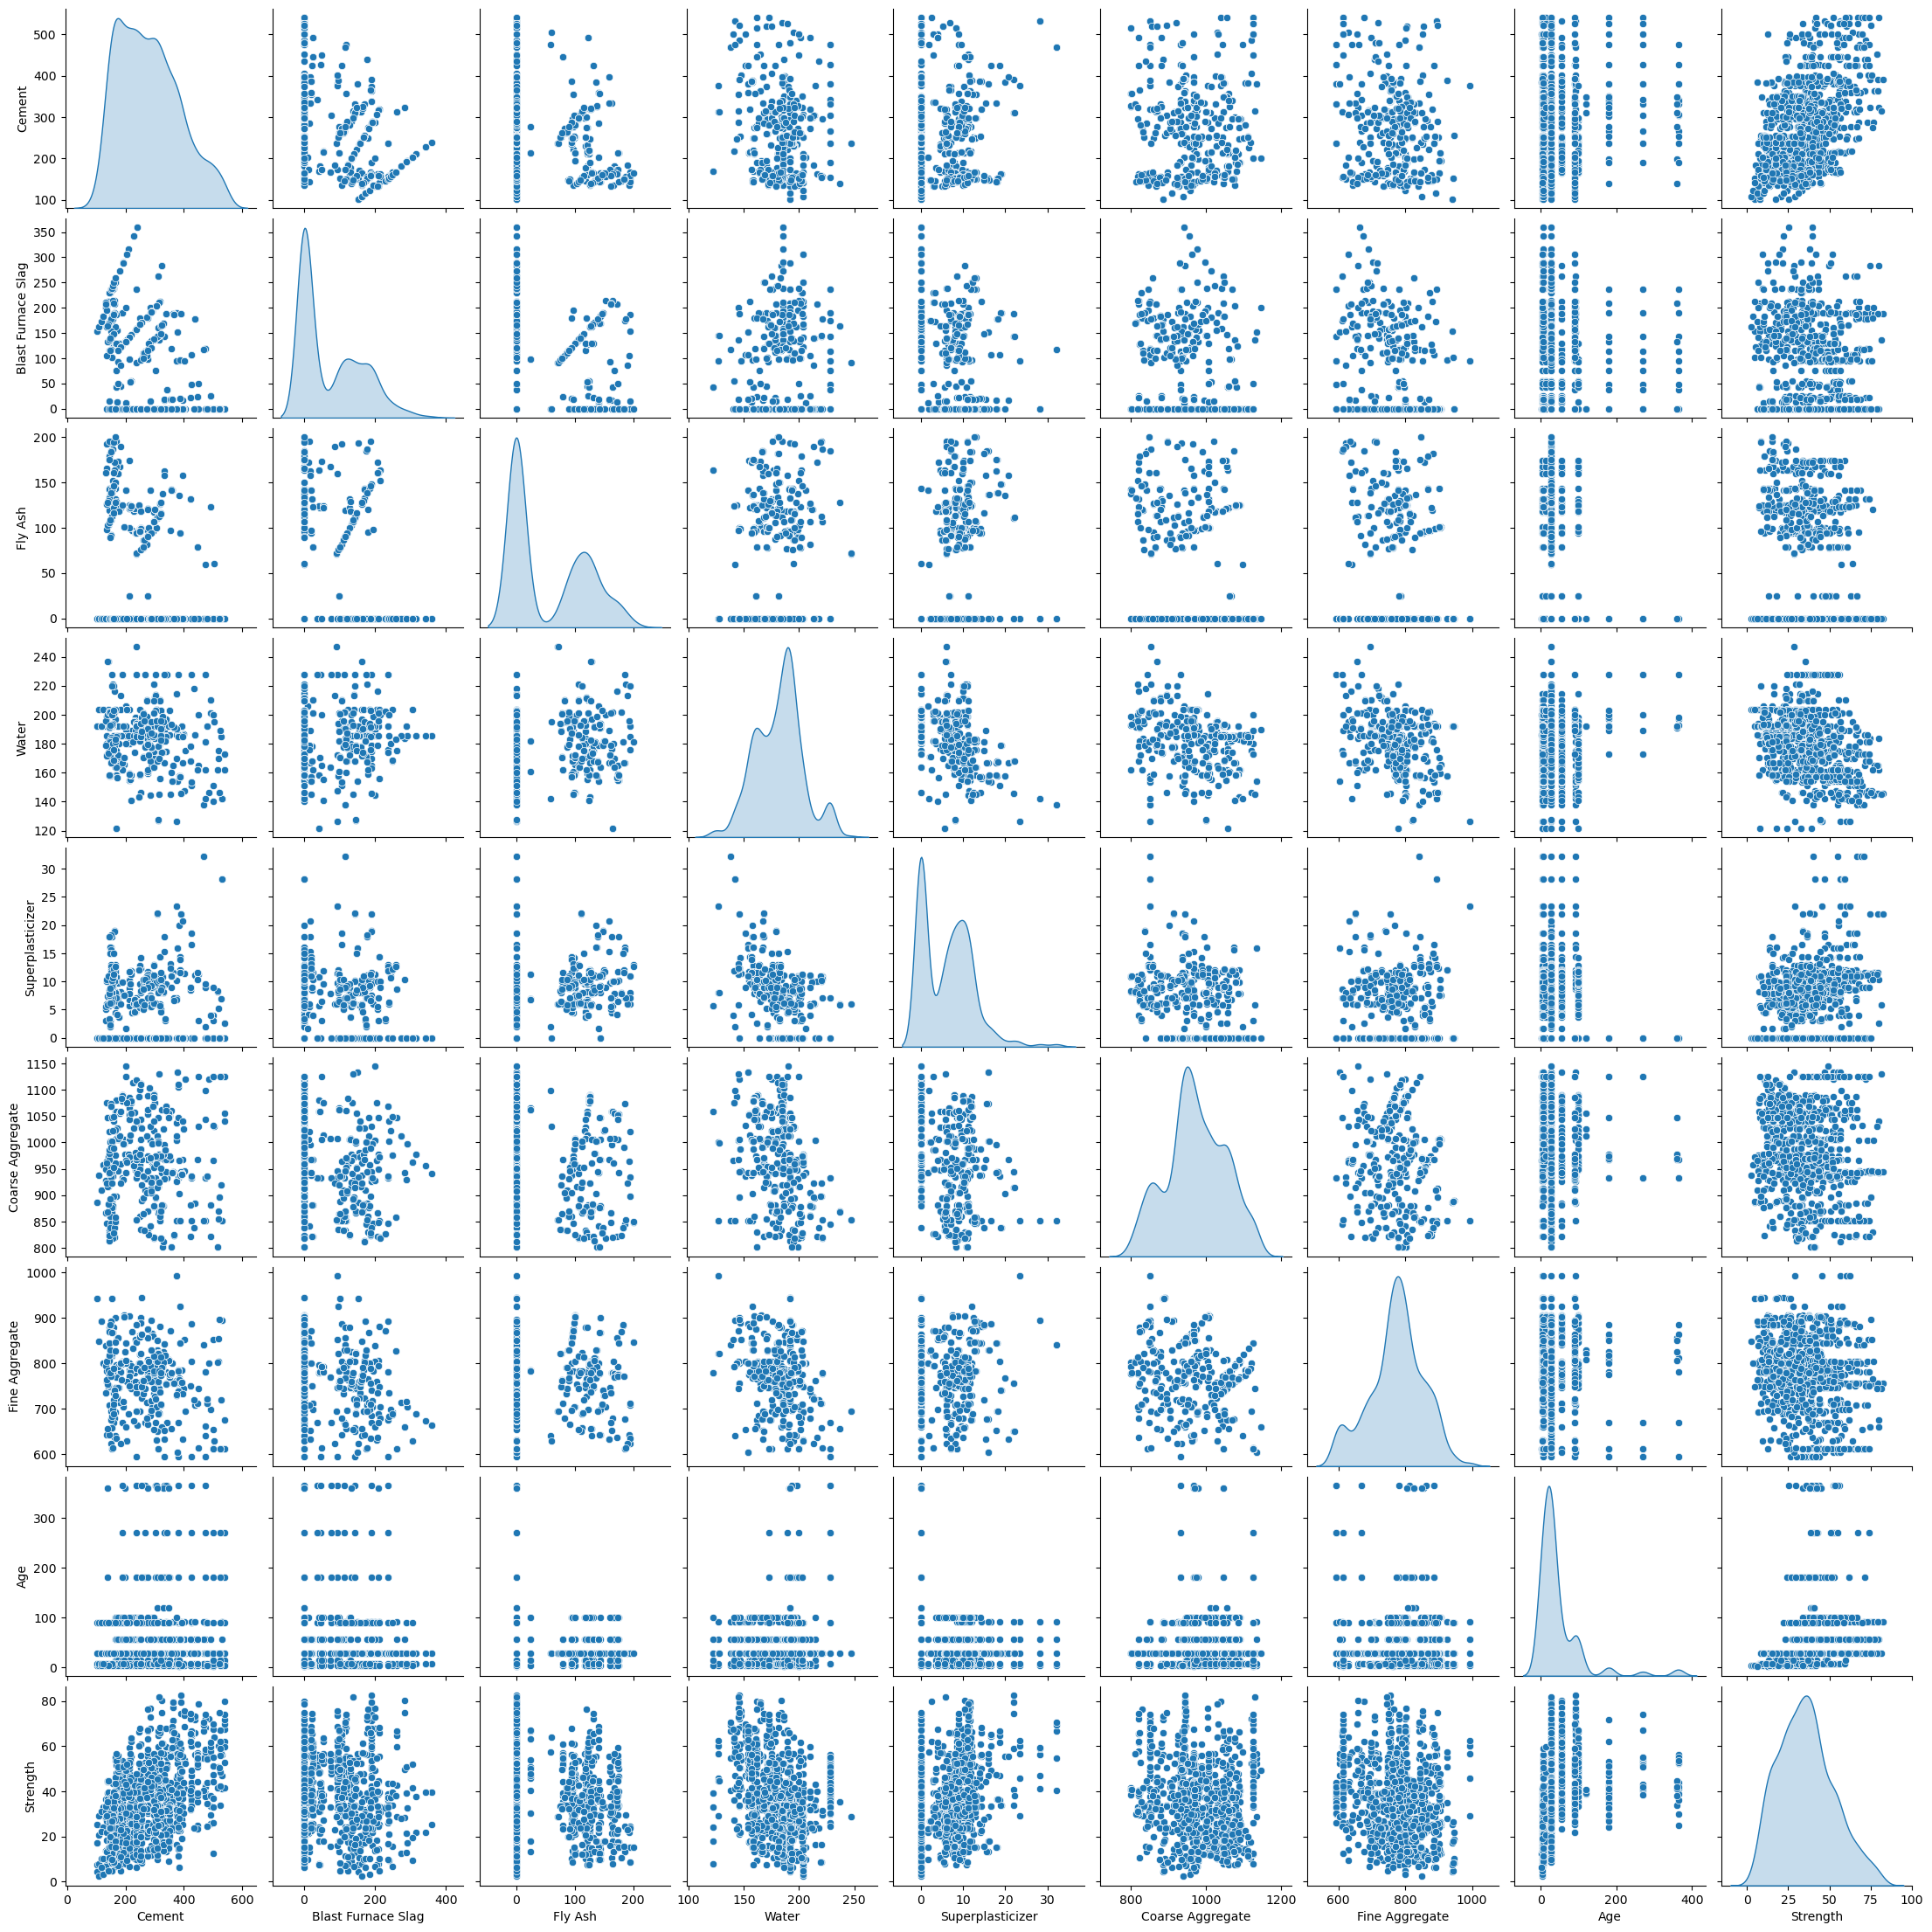

In [71]:
# now lets analyse the data

sns.pairplot(data,diag_kind="kde")

In [72]:
# as we can see the diagonal col -- distribution is very bad

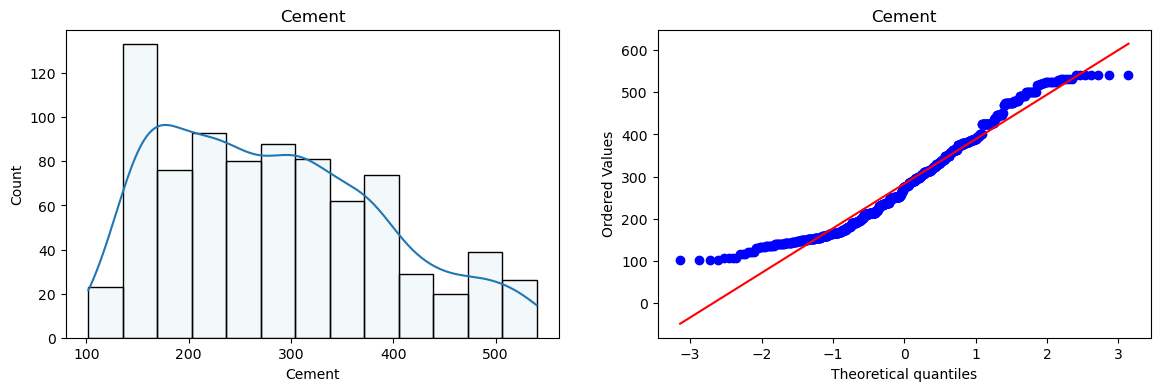

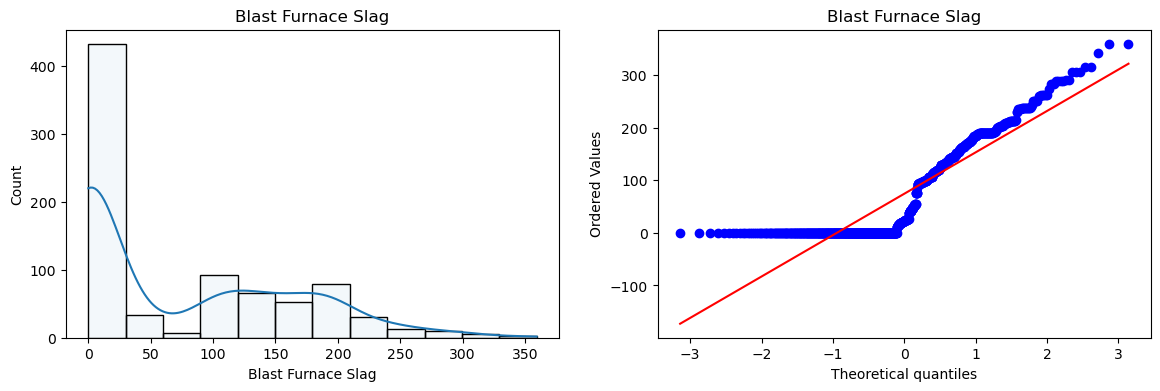

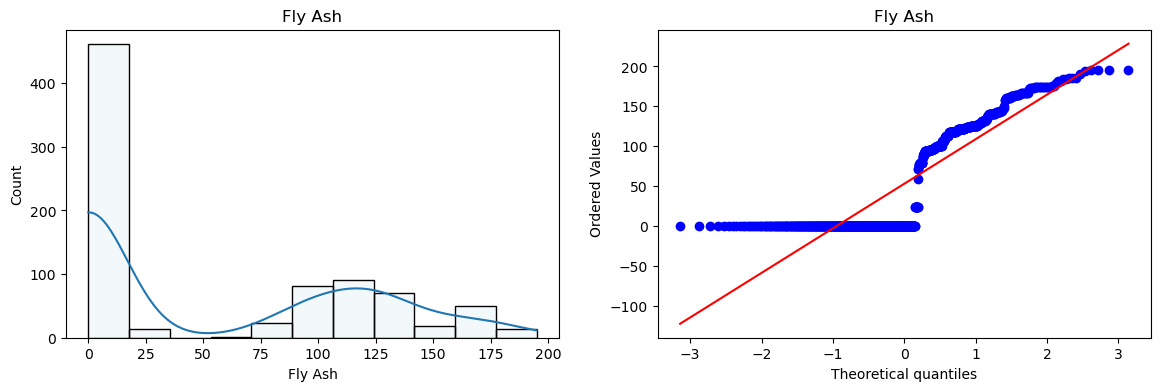

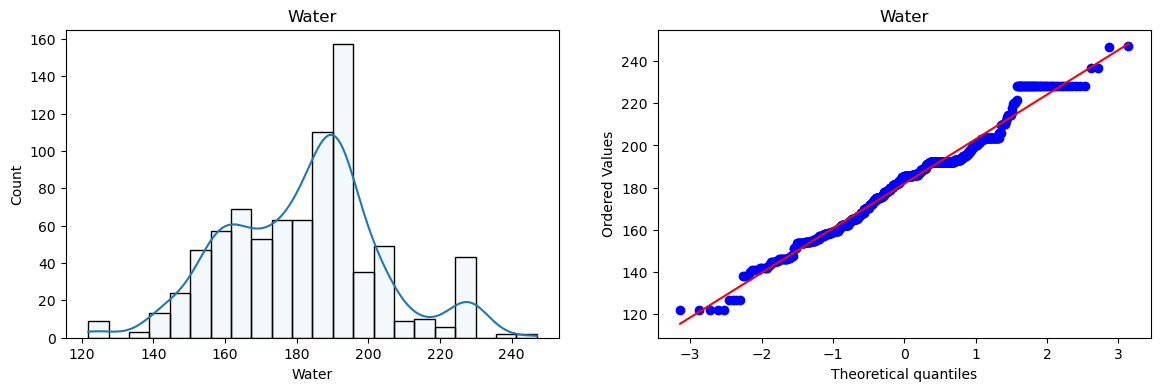

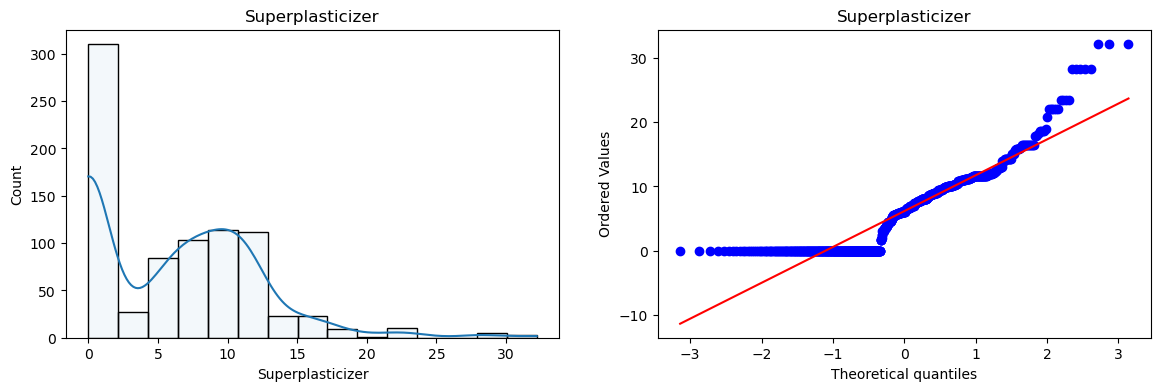

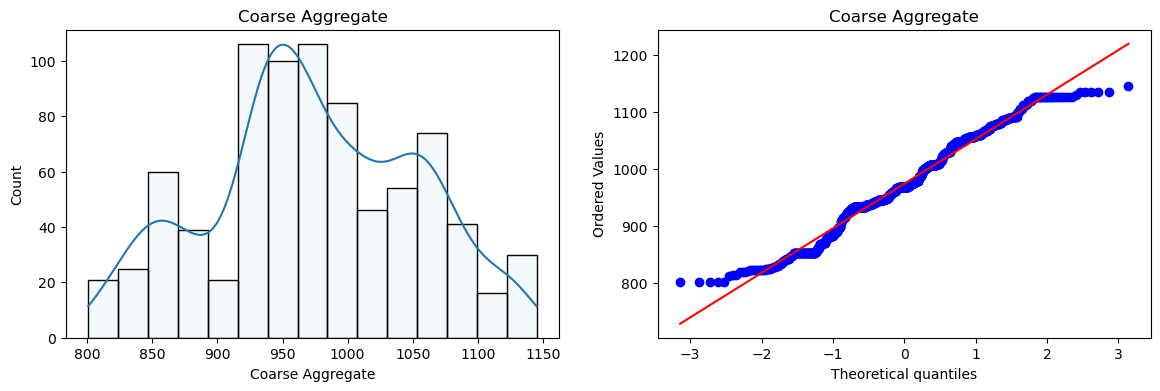

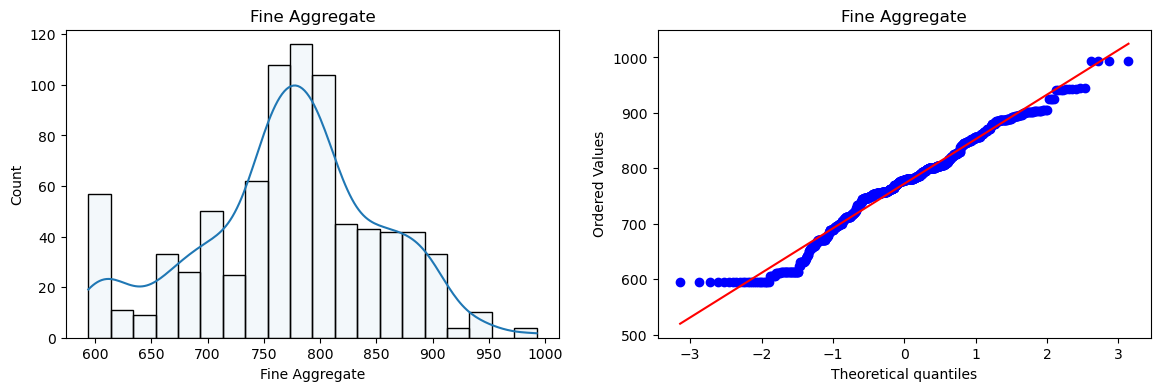

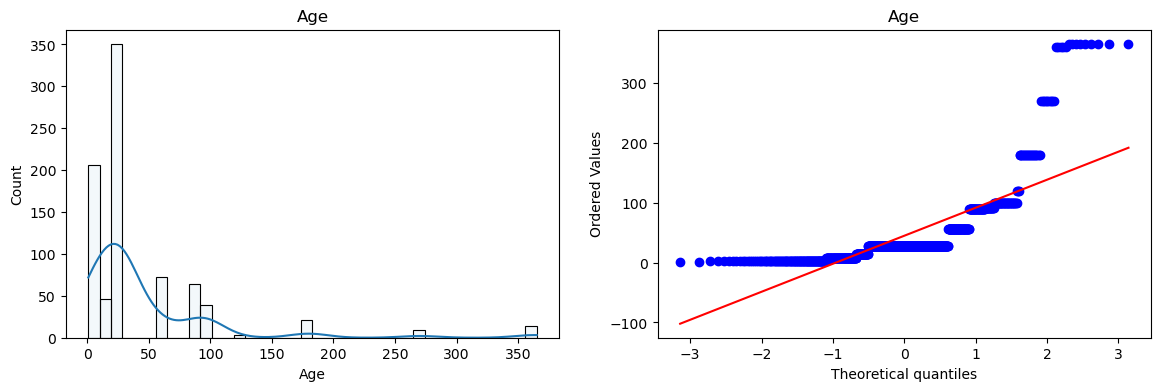

In [73]:
# we can also see these one by one to better analysis

for col in x_train.columns:
    plt.figure(figsize=(14,4))
    plt.subplot(121)
    sns.histplot(x_train[col], kde=True, alpha=0.05)
    plt.title(col)

    plt.subplot(122)
    stats.probplot(x_train[col], dist="norm", plot=plt)
    plt.title(col)

    plt.show()

In [74]:
# but my fav analysis :

x_train.skew()

Cement                0.493343
Blast Furnace Slag    0.802065
Fly Ash               0.566038
Water                 0.091973
Superplasticizer      0.897750
Coarse Aggregate     -0.041485
Fine Aggregate       -0.239988
Age                   3.335411
dtype: float64

In [75]:
# any col ranging inside -0.5 to 0.5 need not to be changed

# PowerTransformer
class sklearn.preprocessing.PowerTransformer(method='yeo-johnson', *, standardize=True, copy=True)[source]
Apply a power transform featurewise to make data more Gaussian-like.

Power transforms are a family of parametric, monotonic transformations that are applied to make data more Gaussian-like. This is useful for modeling issues related to heteroscedasticity (non-constant variance), or other situations where normality is desired.

Currently, PowerTransformer supports the Box-Cox transform and the Yeo-Johnson transform. The optimal parameter for stabilizing variance and minimizing skewness is estimated through maximum likelihood.

Box-Cox requires input data to be strictly positive, while Yeo-Johnson supports both positive or negative data.

By default, zero-mean, unit-variance normalization is applied to the transformed data.

For an example visualization, refer to Compare PowerTransformer with other scalers. To see the effect of Box-Cox and Yeo-Johnson transformations on different distributions, see: Map data to a normal distribution.


## Parameters:
method
{‘yeo-johnson’, ‘box-cox’}, default=’yeo-johnson’
The power transform method. Available methods are:

‘yeo-johnson’ [1], works with positive and negative values

‘box-cox’ [2], only works with strictly positive values

standardize
bool, default=True
Set to True to apply zero-mean, unit-variance normalization to the transformed output.

copy
bool, default=True
Set to False to perform inplace computation during transformation.

## Attributes:
lambdas_ndarray of float of shape (n_features,)
The parameters of the power transformation for the selected features.

n_features_in_int
Number of features seen during fit.

# SO no need to standadize


In [76]:
# applying box-cox trf

pt = PowerTransformer(method='box-cox')

x_train_trf = pt.fit_transform(x_train+0.000001)
x_test_trf = pt.fit_transform(x_test+0.000001)

# this small 0.000001 increase will ensure that even if a vlaue is 0 -- it wont break the code 

# since both power transform adjusts lambda -- to see the values of these lambda:

pd.DataFrame({
    'cols':x_train.columns ,
    'box-cox-lambda':pt.lambdas_
})

,cols,box-cox-lambda
0,Cement,0.215602
1,Blast Furnace Slag,0.025996
2,Fly Ash,-0.006544
3,Water,0.959062
4,Superplasticizer,0.103365
5,Coarse Aggregate,1.192492
6,Fine Aggregate,1.973781
7,Age,-0.014692


In [77]:
# lr model on -- transformed data

lr = LinearRegression()
lr.fit(x_train_trf,y_train)

y_pred2 = lr.predict(x_test_trf)

r2_score(y_test, y_pred2)

0.8055321001972293

In [78]:
# lets cross validate

pt = PowerTransformer(method='box-cox')
x_trf = pt.fit_transform(x + 0.000001)

lr = LinearRegression()

np.mean(cross_val_score(lr, x_trf,y, scoring='r2', cv=10))

0.6466764749006959

In [79]:
# so as we can see all accuracy actually improved

In [80]:
# now lets again see the graph for each col

# x_train_trf = pd.DataFrame(x_train_trf,columns=X_train.columns)

for col in x_train_trf.columns:
    plt.figure(figsize=(14,4))
    plt.subplot(121)
    sns.distplot(x_train[col])
    plt.title(col)

    plt.subplot(122)
    sns.distplot(x_train_trf[col])
    plt.title(col)

    plt.show()

AttributeError: 'numpy.ndarray' object has no attribute 'columns'

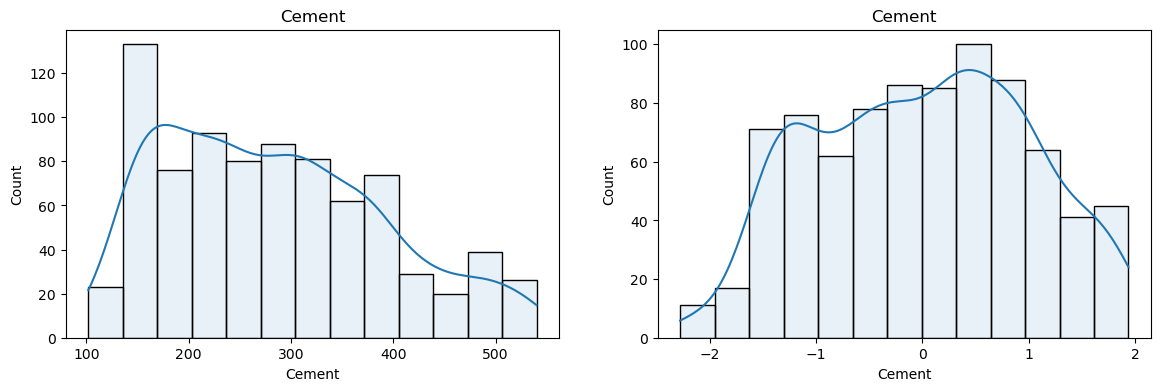

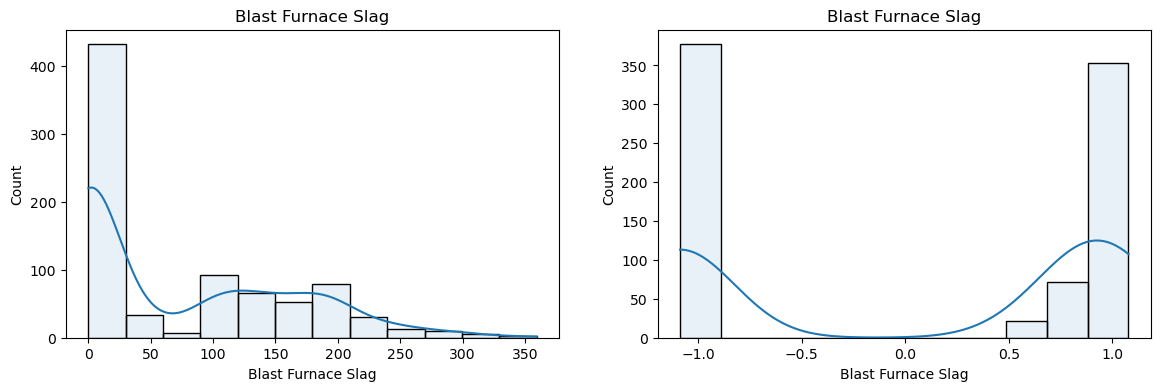

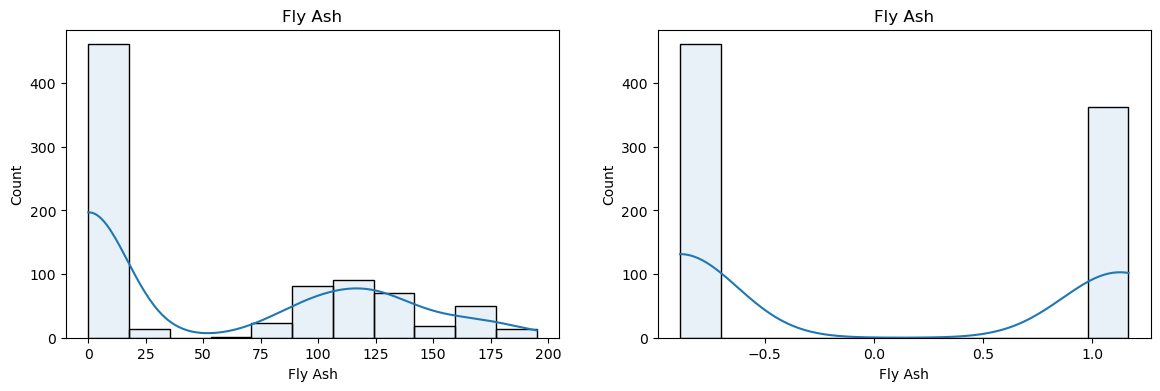

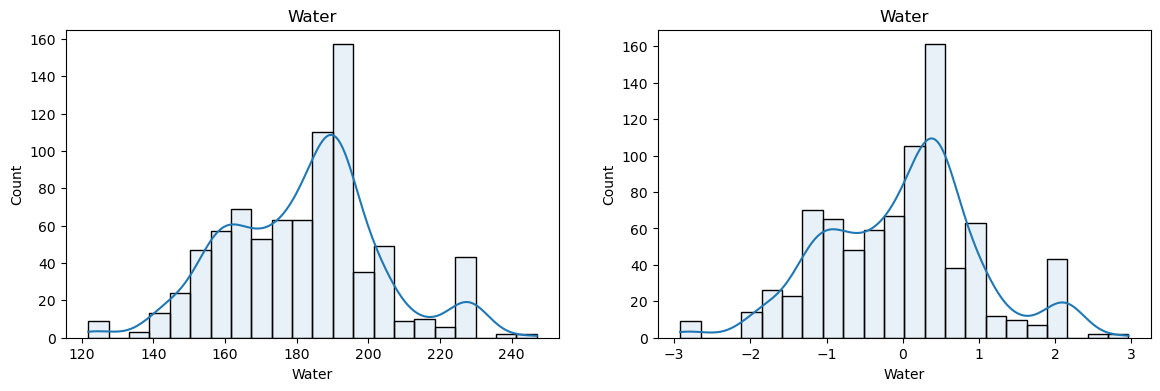

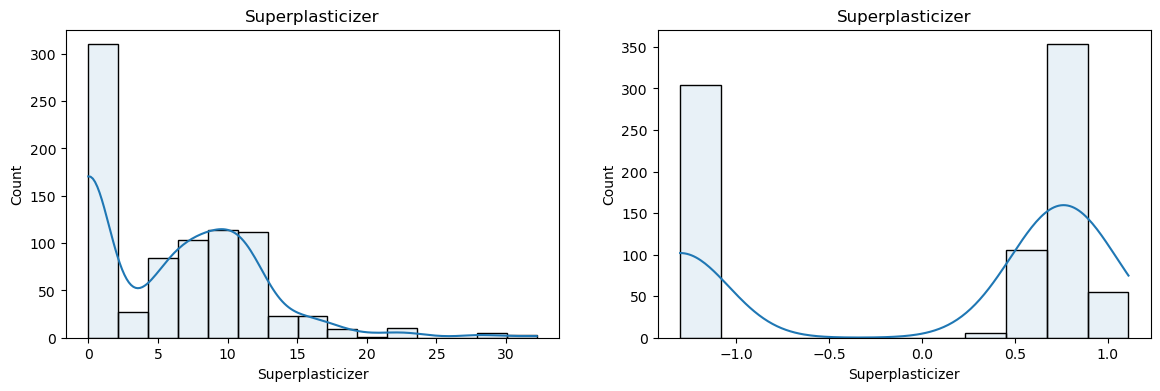

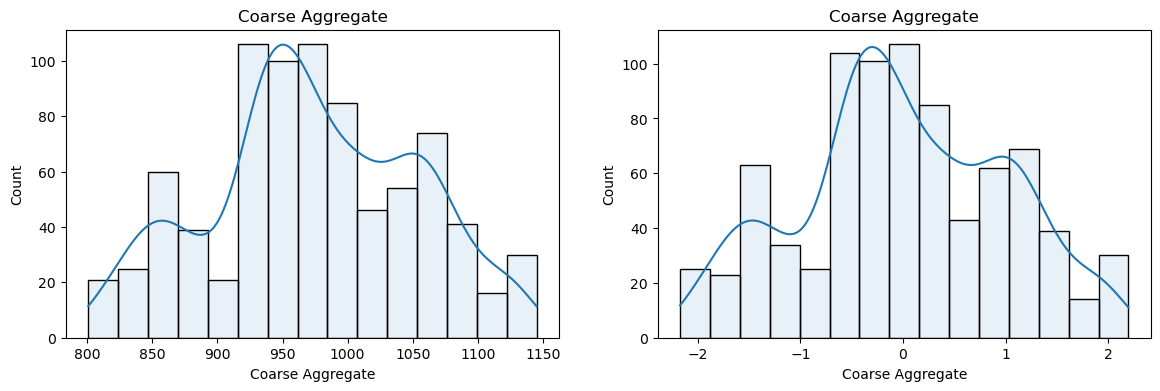

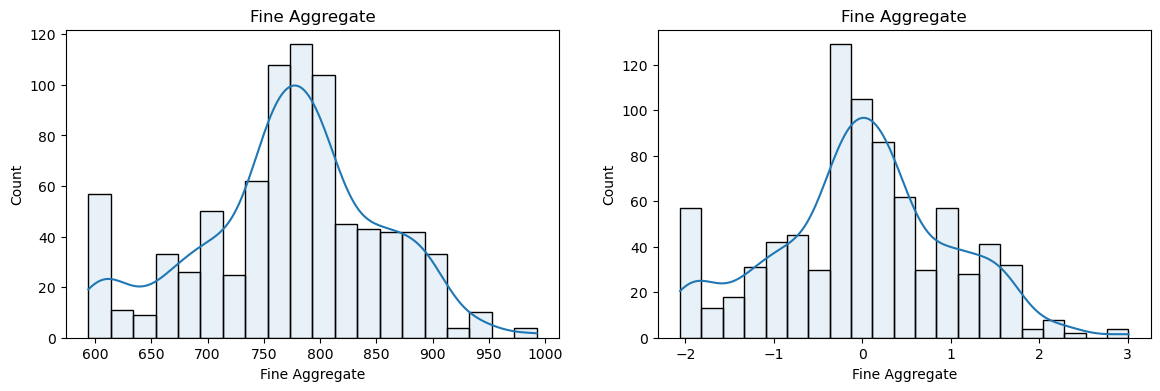

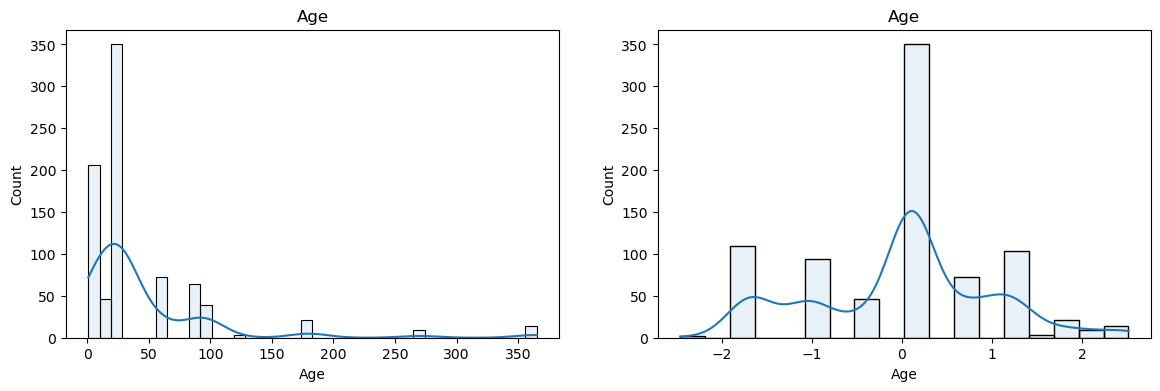

In [81]:
x_train_trf = pd.DataFrame(x_train_trf,columns=x_train.columns)

for col in x_train_trf.columns:
    plt.figure(figsize=(14,4))
    plt.subplot(121)
    sns.histplot(x_train[col], kde=True, alpha=0.1)
    plt.title(col)

    plt.subplot(122)
    sns.histplot(x_train_trf[col], kde=True, alpha=0.1)
    plt.title(col)

    plt.show()

## Applying Yeo-Johnson -- best and also by default in powertransformer

In [84]:
# Apply Yeo-Johnson transform

pt2 = PowerTransformer()

x_train_trf2 = pt2.fit_transform(x_train)
X_test_trf2 = pt2.transform(x_test)

lr = LinearRegression()
lr.fit(x_train_trf2,y_train)

y_pred3 = lr.predict(X_test_trf2)

print(r2_score(y_test,y_pred3))

pd.DataFrame({'cols':x_train.columns,'Yeo_Johnson_lambdas':pt2.lambdas_})

0.8161906513339304


,cols,Yeo_Johnson_lambdas
0,Cement,0.174348
1,Blast Furnace Slag,0.015715
2,Fly Ash,-0.161447
3,Water,0.771307
4,Superplasticizer,0.253935
5,Coarse Aggregate,1.130050
6,Fine Aggregate,1.783100
7,Age,0.019885


In [85]:
# applying cross val score

pt = PowerTransformer()
x_transformed2 = pt.fit_transform(x)

lr = LinearRegression()
np.mean(cross_val_score(lr,x_transformed2,y,scoring='r2'))

0.6834625141500862

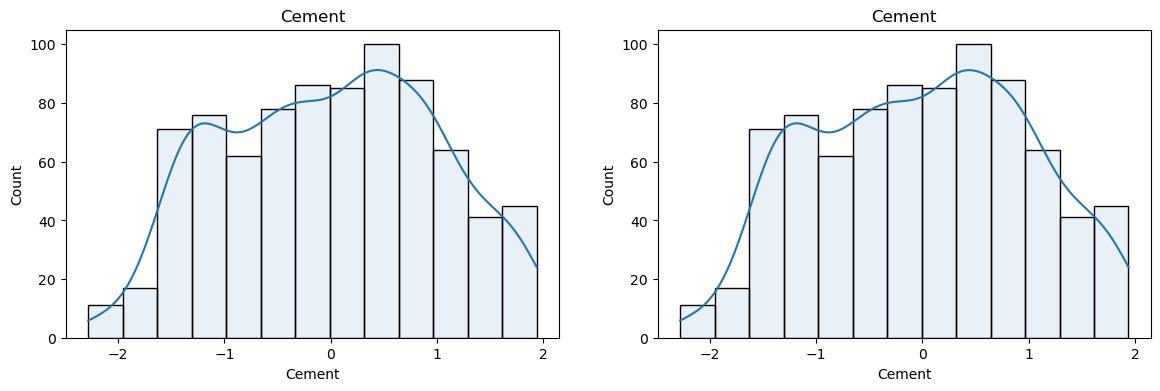

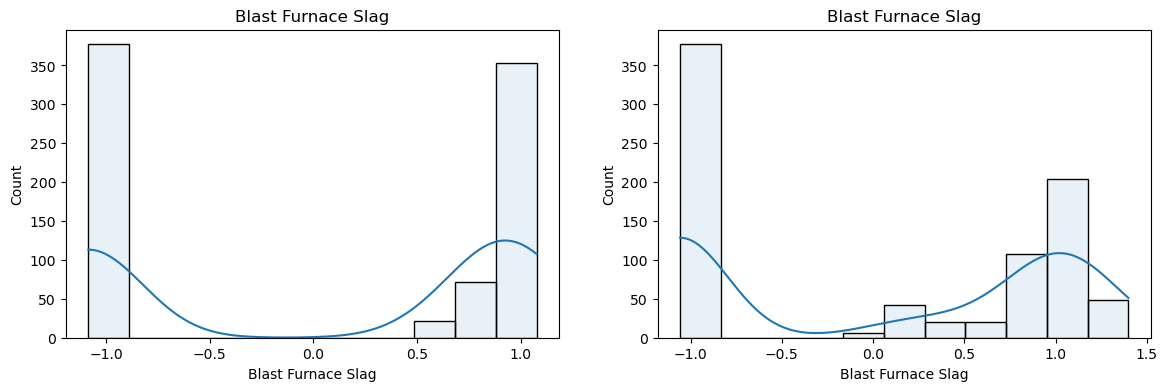

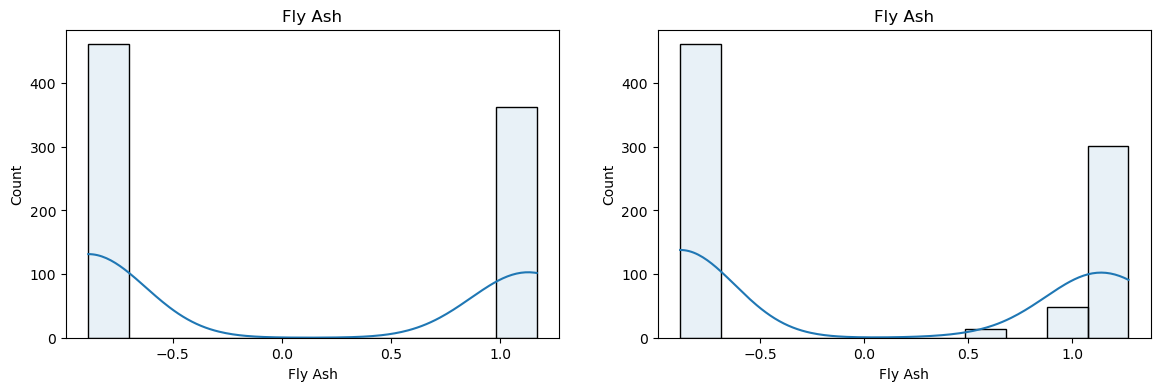

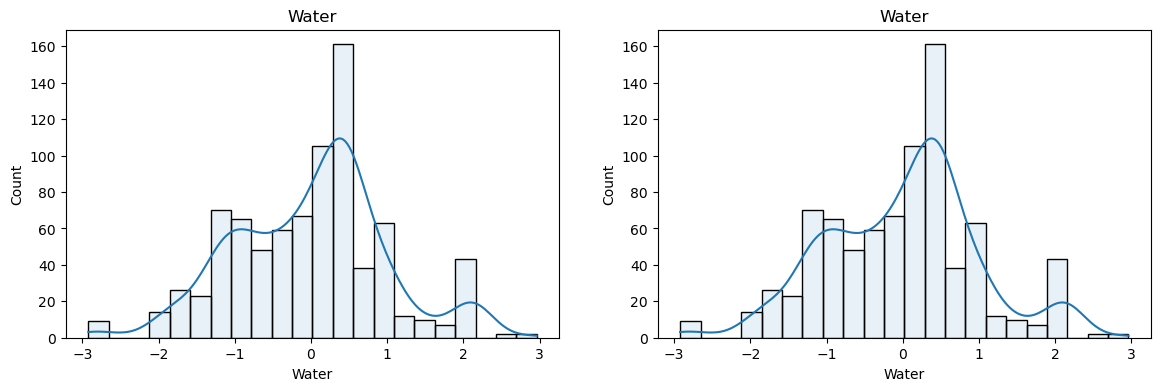

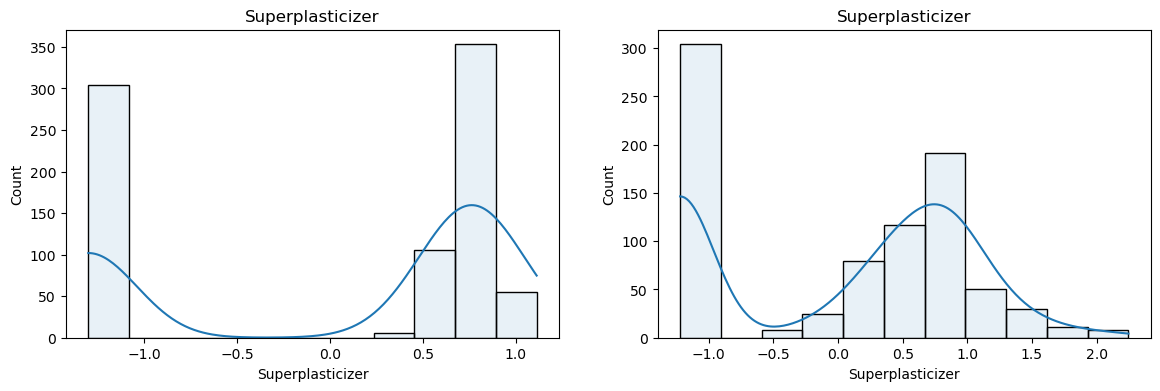

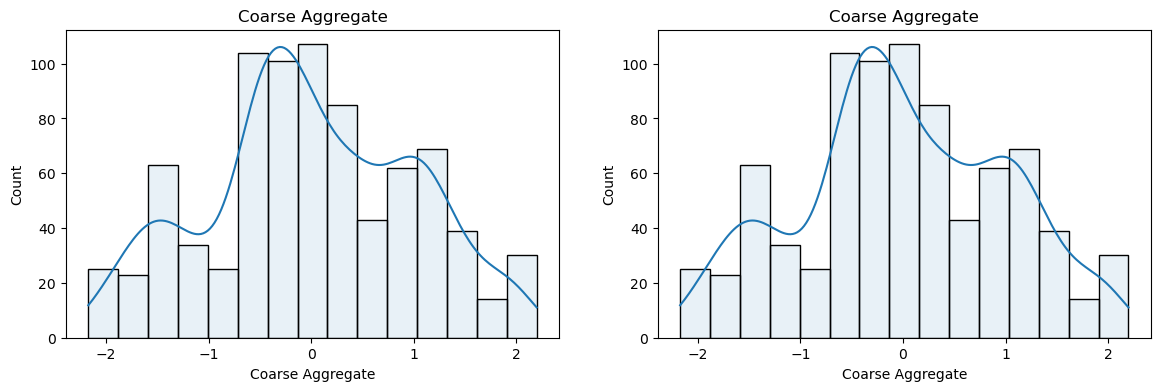

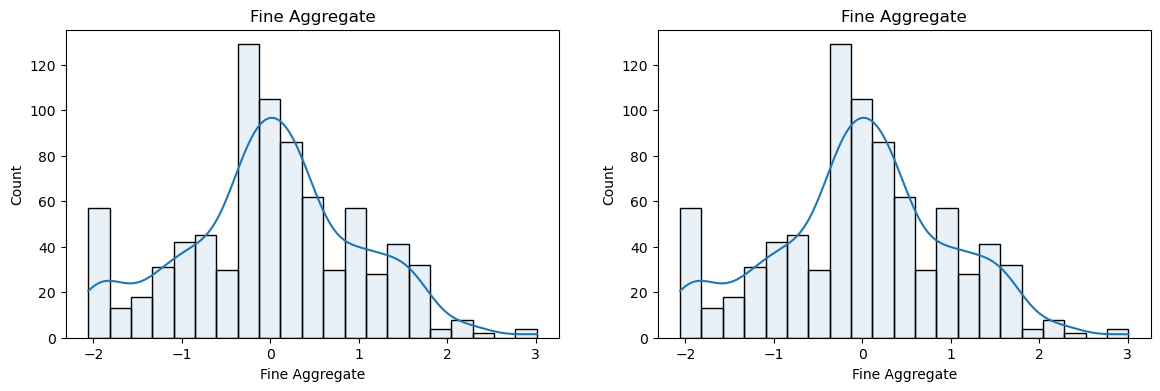

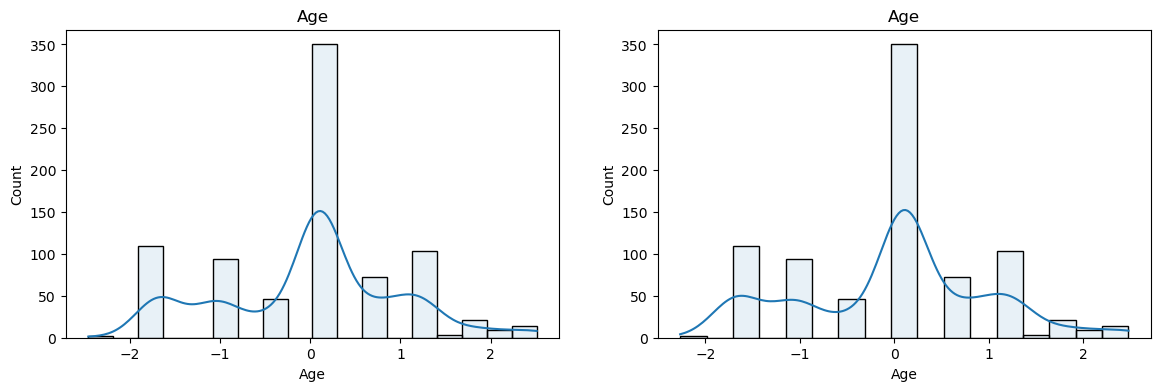

In [90]:
# Before and after comparision for Yeo-Johnson


x_train_trf2 = pd.DataFrame(x_train_trf2,columns=x_train.columns)


for col in x_train_trf2.columns:
    plt.figure(figsize=(14,4))
    plt.subplot(121)
    sns.histplot(x_train_trf[col],kde=True,alpha=0.1)
    plt.title(col)

    plt.subplot(122)
    sns.histplot(x_train_trf2[col],kde=True,alpha=0.1)
    plt.title(col)

    plt.show()

In [92]:
# Side by side Lambdas

pd.DataFrame({'cols':x_train.columns,'box_cox_lambdas':pt.lambdas_,'Yeo_Johnson_lambdas':pt2.lambdas_})

,cols,box_cox_lambdas,Yeo_Johnson_lambdas
0,Cement,0.169544,0.174348
1,Blast Furnace Slag,0.016633,0.015715
2,Fly Ash,-0.136480,-0.161447
3,Water,0.808438,0.771307
4,Superplasticizer,0.264160,0.253935
5,Coarse Aggregate,1.129395,1.130050
6,Fine Aggregate,1.830763,1.783100
7,Age,0.001771,0.019885


In [93]:
# done✅